### Task 1: Designing a Heuristic for a Warehouse Robot

In [ ]:
import math
import networkx as nx
import matplotlib.pyplot as plt

locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}

warehouse_graph = {
    "Receiving_Area": {"Storage_A": 2.2, "Storage_B": 4.1},
    "Storage_A": {"Sorting_Area": 2.2},
    "Storage_B": {"Inspection_Area": 5.0, "Sorting_Area": 6.0},
    "Sorting_Area": {"Inspection_Area": 3.2, "Packing_Station": 6.0},
    "Inspection_Area": {"Packing_Station": 3.2},
    "Packing_Station": {}
}

def heuristic(current, goal):
    return math.dist(locations[current], locations[goal])

goal = "Packing_Station"
print(f"{'Location':20} {'h(n)':>8}")
for location in locations:
    print(f"{location:20} {heuristic(location, goal):8.2f}")


Location                 h(n)
Receiving_Area           9.22
Storage_A                7.07
Storage_B                6.32
Sorting_Area             5.00
Inspection_Area          2.24
Packing_Station          0.00


#### Warehouse graph and minimum-cost path



Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 10.40


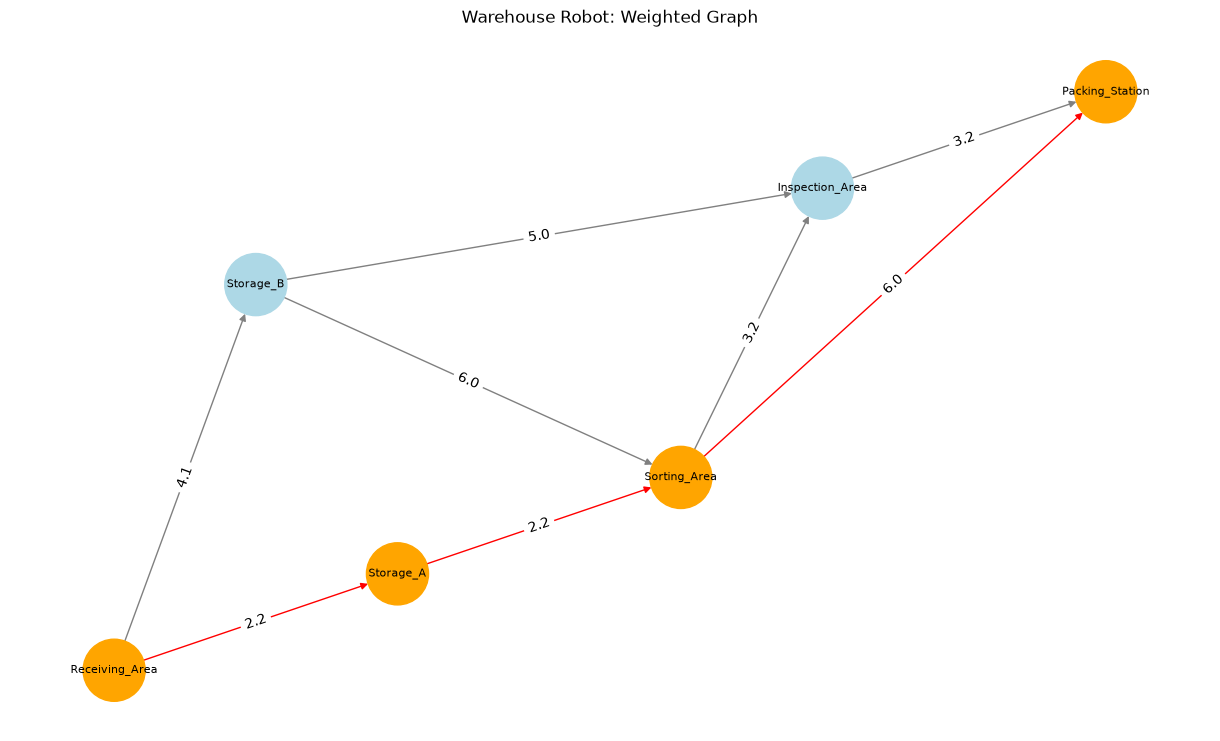

In [ ]:
G = nx.DiGraph()
for node, neighbors in warehouse_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

solution_path = nx.shortest_path(G, source="Receiving_Area", target="Packing_Station", weight="weight")
solution_cost = nx.shortest_path_length(G, source="Receiving_Area", target="Packing_Station", weight="weight")

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")

pos = locations
path_edges = list(zip(solution_path, solution_path[1:]))
node_colors = ["orange" if n in solution_path else "lightblue" for n in G.nodes()]
edge_colors = ["red" if e in path_edges else "gray" for e in G.edges()]

plt.figure(figsize=(12, 7))
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors,
        node_size=2000, font_size=8, arrows=True)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels)
plt.title("Warehouse Robot: Weighted Graph")
plt.axis("off")
plt.show()

In [ ]:
print(f"{'Edge':43} {'h(n)':>7} {'Cost + h(m)':>13} {'Consistent':>11}")
for node, neighbors in warehouse_graph.items():
    for neighbor, cost in neighbors.items():
        left = heuristic(node, goal)
        right = cost + heuristic(neighbor, goal)
        print(f"{node + ' → ' + neighbor:43} {left:7.2f} {right:13.2f} {str(left <= right + 1e-9):>11}")

true_costs = {node: nx.shortest_path_length(G, node, goal, weight='weight') for node in locations}
print('Admissible for all nodes:', all(heuristic(node, goal) <= true_costs[node] + 1e-9 for node in locations))


Edge                                           h(n)   Cost + h(m)  Consistent
Receiving_Area → Storage_A                     9.22          9.27        True
Receiving_Area → Storage_B                     9.22         10.42        True
Storage_A → Sorting_Area                       7.07          7.20        True
Storage_B → Inspection_Area                    6.32          7.24        True
Storage_B → Sorting_Area                       6.32         11.00        True
Sorting_Area → Inspection_Area                 5.00          5.44        True
Sorting_Area → Packing_Station                 5.00          6.00        True
Inspection_Area → Packing_Station              2.24          3.20        True
Admissible for all nodes: True


**Observation:** Euclidean distance estimates straight-line proximity to the Packing Station. On this graph, it is admissible and every edge satisfies `h(n) ≤ cost(n,m) + h(m)`, so it is also consistent. The printed edge checks and shortest remaining costs verify both properties.


### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [ ]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6)
}

airport_graph = {
    "Baggage_Area": {"Security": 2.2, "Checkpoint": 4.1},
    "Security": {"Food_Court": 2.2},
    "Checkpoint": {"Terminal_Hall": 5.0},
    "Food_Court": {"Terminal_Hall": 3.2, "Departure_Gate": 6.0},
    "Terminal_Hall": {"Departure_Gate": 3.2},
    "Departure_Gate": {}
}

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def greedy_best_first_search(start, goal, graph):
    counter = 0
    open_set = []
    heapq.heappush(open_set, (heuristic(start, goal), counter, start))
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while open_set:
        _, _, current = heapq.heappop(open_set)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)
        if current == goal:
            break
        for neighbor in graph.get(current, {}):
            if neighbor not in visited:
                counter += 1
                heapq.heappush(open_set, (heuristic(neighbor, goal), counter, neighbor))
                if neighbor not in came_from:
                    came_from[neighbor] = current

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = came_from.get(current)
    path.reverse()

    total_cost = sum(graph[path[i]][path[i+1]] for i in range(len(path)-1))
    return path, total_cost, expansion_order

start = "Baggage_Area"
goal = "Departure_Gate"
path, total_cost, expansion_order = greedy_best_first_search(start, goal, airport_graph)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))
print("\nSolution path:")
print(" -> ".join(path))
print(f"\nTotal path cost: {total_cost:.2f}")

GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30


#### Airport graph and GBFS path


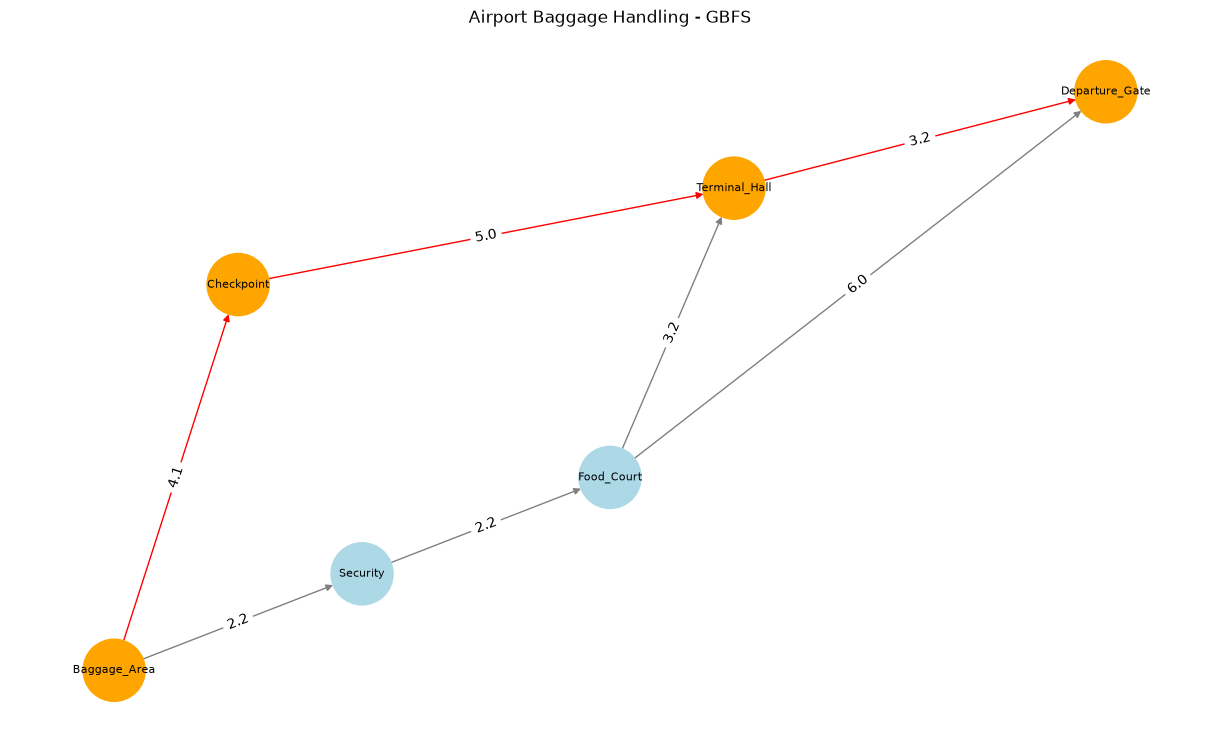

In [5]:
G = nx.DiGraph()
for node, neighbors in airport_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

pos = locations
path_edges = list(zip(path, path[1:]))
node_colors = ["orange" if n in path else "lightblue" for n in G.nodes()]
edge_colors = ["red" if e in path_edges else "gray" for e in G.edges()]

plt.figure(figsize=(12, 7))
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors,
        node_size=2000, font_size=8, arrows=True)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels)
plt.title("Airport Baggage Handling - GBFS")
plt.axis("off")
plt.show()

**Why GBFS chose this route:** From `Baggage_Area`, `Checkpoint` has a lower estimated distance to `Departure_Gate` than `Security`. It then selects `Terminal_Hall` and the goal. GBFS ignores edge costs when ranking nodes, so its 12.30 route is more expensive than the 10.40 route through `Security` and `Food_Court`.


### Task 3: A* Search for Emergency Supply Robot

In [ ]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}

hospital_graph = {
    "Pharmacy": {"Main_Corridor": 2.2, "Patient_Wing": 4.1},
    "Main_Corridor": {"Nursing_Station": 2.2},
    "Patient_Wing": {"Laboratory": 5.0},
    "Nursing_Station": {"Laboratory": 3.2, "Emergency_Ward": 6.0},
    "Laboratory": {"Emergency_Ward": 3.2},
    "Emergency_Ward": {}
}

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def reconstruct_path(came_from, current):
    path = []
    while current is not None:
        path.append(current)
        current = came_from.get(current)
    path.reverse()
    return path

def a_star_search(start, goal, graph):
    counter = 0
    open_set = []
    heapq.heappush(open_set, (heuristic(start, goal), counter, start))
    came_from = {start: None}
    g_cost = {start: 0}
    expansion_order = []
    closed = set()

    while open_set:
        f, _, current = heapq.heappop(open_set)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)
        if current == goal:
            break
        for neighbor, cost in graph.get(current, {}).items():
            if neighbor in closed:
                continue
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                f_val = new_g + heuristic(neighbor, goal)
                counter += 1
                heapq.heappush(open_set, (f_val, counter, neighbor))
                came_from[neighbor] = current

    path = reconstruct_path(came_from, goal)
    total_cost = g_cost.get(goal, float('inf'))
    return path, total_cost, expansion_order, g_cost

start = "Pharmacy"
goal = "Emergency_Ward"
path, total_cost, expansion_order, g_cost = a_star_search(start, goal, hospital_graph)

print("A* Search")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))
print("\nSolution path:")
print(" -> ".join(path))
print(f"\nTotal path cost: {total_cost:.2f}")

A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 10.40


#### Selected A* nodes


In [7]:
print("\nA* Node Information")
print("*********************")
print(f"{'Node':20s}{'g(n)':>10s}{'h(n)':>10s}{'f(n)':>10s}")
for node in expansion_order:
    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h
    print(f"{node:20s}{g:10.2f}{h:10.2f}{f:10.2f}")


A* Node Information
*********************
Node                      g(n)      h(n)      f(n)
Pharmacy                  0.00     10.00     10.00
Main_Corridor             2.20      7.81     10.01
Nursing_Station           4.40      5.66     10.06
Emergency_Ward           10.40      0.00     10.40


#### Hospital graph and A* path


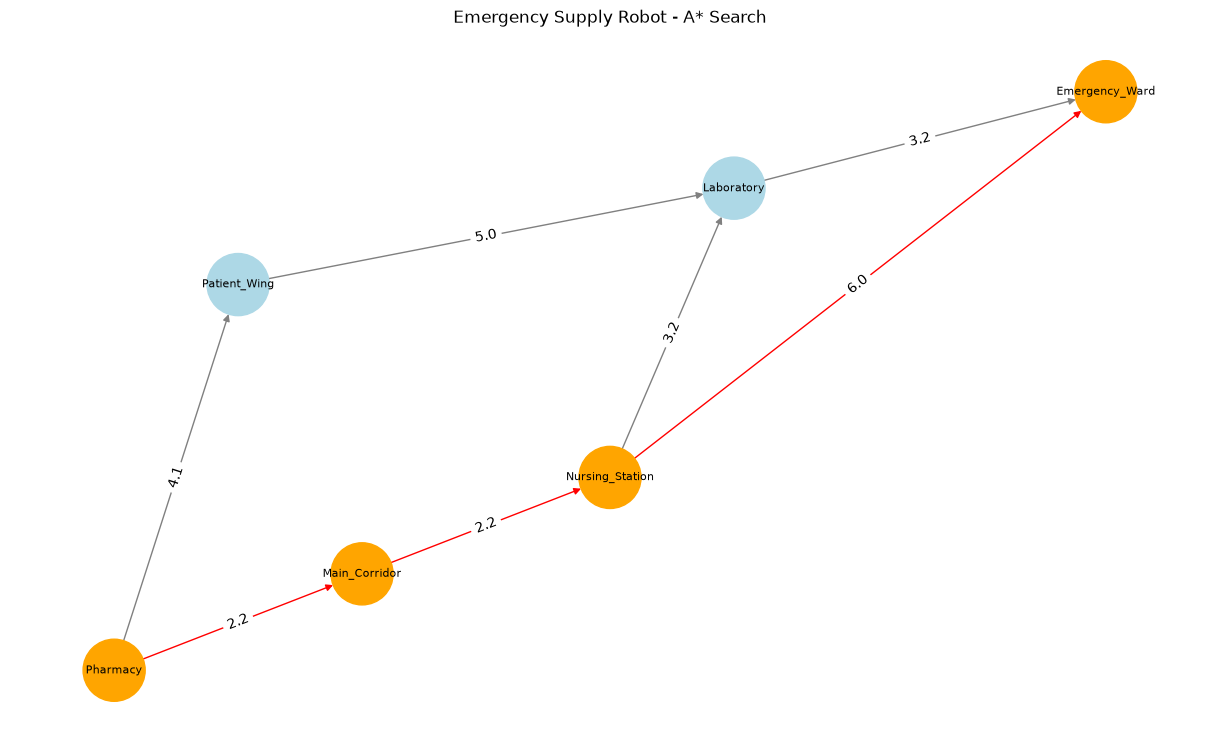

In [8]:
G = nx.DiGraph()
for node, neighbors in hospital_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

pos = locations
path_edges = list(zip(path, path[1:]))
node_colors = ["orange" if n in path else "lightblue" for n in G.nodes()]
edge_colors = ["red" if e in path_edges else "gray" for e in G.edges()]

plt.figure(figsize=(12, 7))
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors,
        node_size=2000, font_size=8, arrows=True)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels)
plt.title("Emergency Supply Robot - A* Search")
plt.axis("off")
plt.show()

**Comparison:** GBFS chooses the smallest remaining-distance estimate. A* adds the cost already travelled, so it can avoid a visually close but expensive route. For this hospital graph, A* finds `Pharmacy → Main_Corridor → Nursing_Station → Emergency_Ward` at cost 10.40.


### Task 4: Weighted A* for Autonomous Delivery Drone

In [9]:
import math
import heapq
import pandas as pd

locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (1, 6),
    "Zone_D": (3, 6),
    "Customer_Building": (7, 6)
}

graph = {
    "Distribution_Center": {"Zone_A": 2.2, "Zone_B": 3.0},
    "Zone_A": {"Zone_C": 2.2},
    "Zone_B": {"Zone_D": 5.0},
    "Zone_C": {"Customer_Building": 6.0},
    "Zone_D": {"Customer_Building": 3.2},
    "Customer_Building": {}
}

def heuristic(node, goal):
    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

goal = "Customer_Building"

heuristic_data = [{"Node": n, "h(n)": round(heuristic(n, goal), 2)} for n in locations]
heuristic_df = pd.DataFrame(heuristic_data)
print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

Heuristic Values:
               Node  h(n)
Distribution_Center  9.22
             Zone_A  7.07
             Zone_B  6.32
             Zone_C  6.00
             Zone_D  4.00
  Customer_Building  0.00


In [10]:
def weighted_a_star(start, goal, graph, weight):
    counter = 0
    open_set = []
    heapq.heappush(open_set, (0, counter, start))
    came_from = {start: None}
    g_cost = {start: 0}
    expansion_order = []
    closed = set()

    while open_set:
        f, _, current = heapq.heappop(open_set)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)
        if current == goal:
            break
        for neighbor, cost in graph.get(current, {}).items():
            if neighbor in closed:
                continue
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                f_val = new_g + weight * heuristic(neighbor, goal)
                counter += 1
                heapq.heappush(open_set, (f_val, counter, neighbor))
                came_from[neighbor] = current

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = came_from.get(current)
    path.reverse()

    return path, g_cost.get(goal, float('inf')), expansion_order

start = "Distribution_Center"
goal = "Customer_Building"
weights = [1, 1.5, 2, 3]
results = []

for w in weights:
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)
    results.append({
        "Weight": w,
        "Solution Path": " \u2192 ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " \u2192 ".join(expansion_order)
    })

results_df = pd.DataFrame(results)
print(results_df[["Weight", "Solution Path", "Total Cost", "Nodes Expanded"]].to_string(index=False))

 Weight                                             Solution Path  Total Cost  Nodes Expanded
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5
    1.5 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4


In [11]:
print("\nDetailed Expansion Orders:")
for r in results:
    print(f"\nw = {r['Weight']}: {r['Expansion Order']}")


Detailed Expansion Orders:

w = 1: Distribution_Center → Zone_A → Zone_B → Zone_C → Customer_Building

w = 1.5: Distribution_Center → Zone_B → Zone_A → Zone_C → Customer_Building

w = 2: Distribution_Center → Zone_B → Zone_D → Customer_Building

w = 3: Distribution_Center → Zone_B → Zone_D → Customer_Building


#### Drone paths by weight


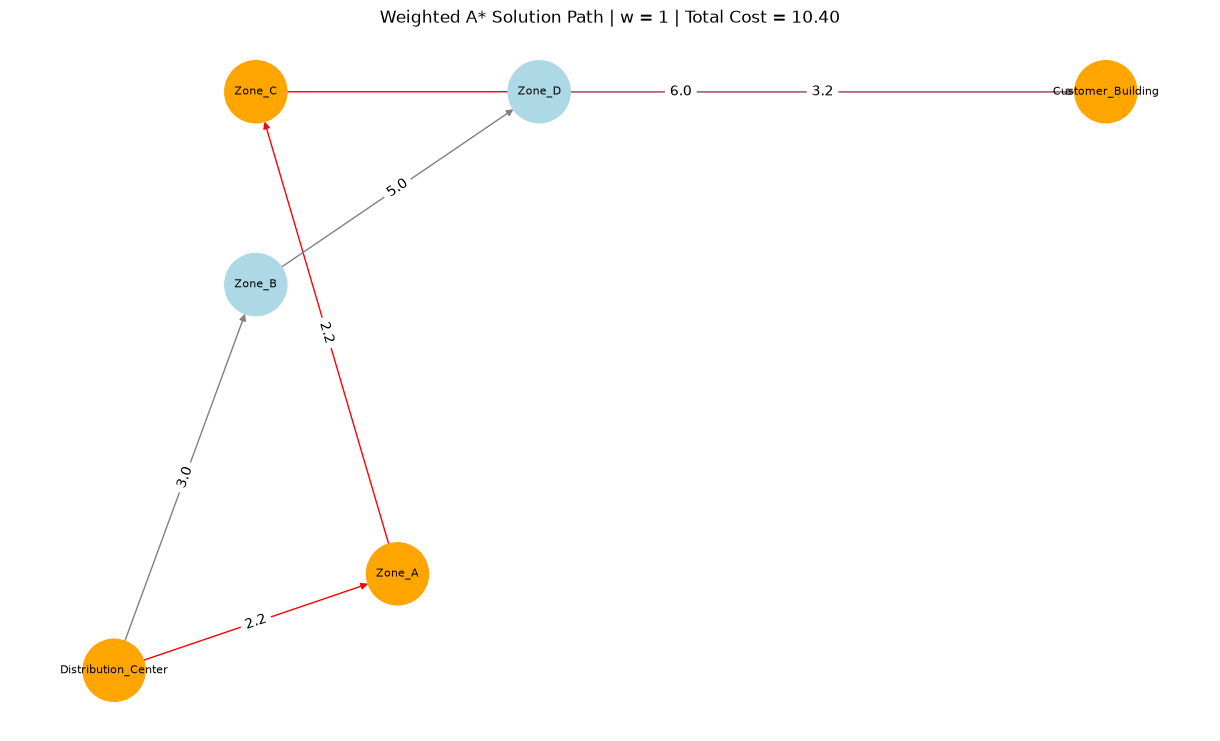

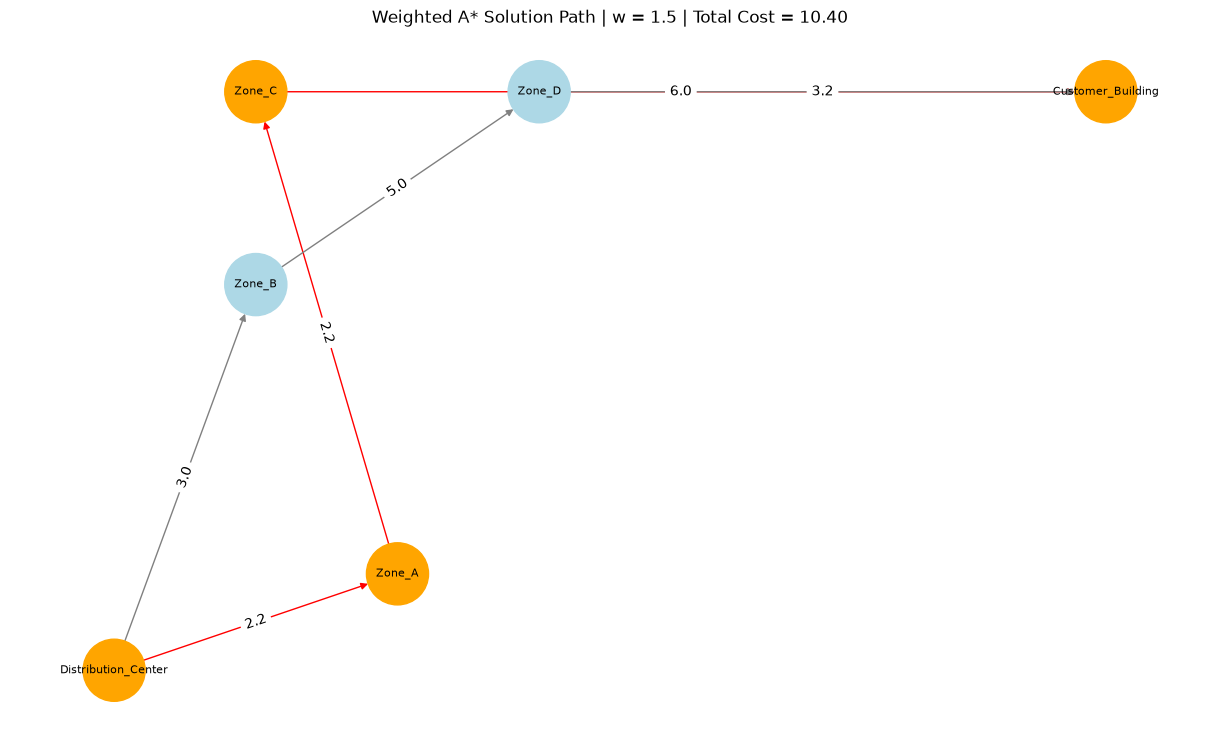

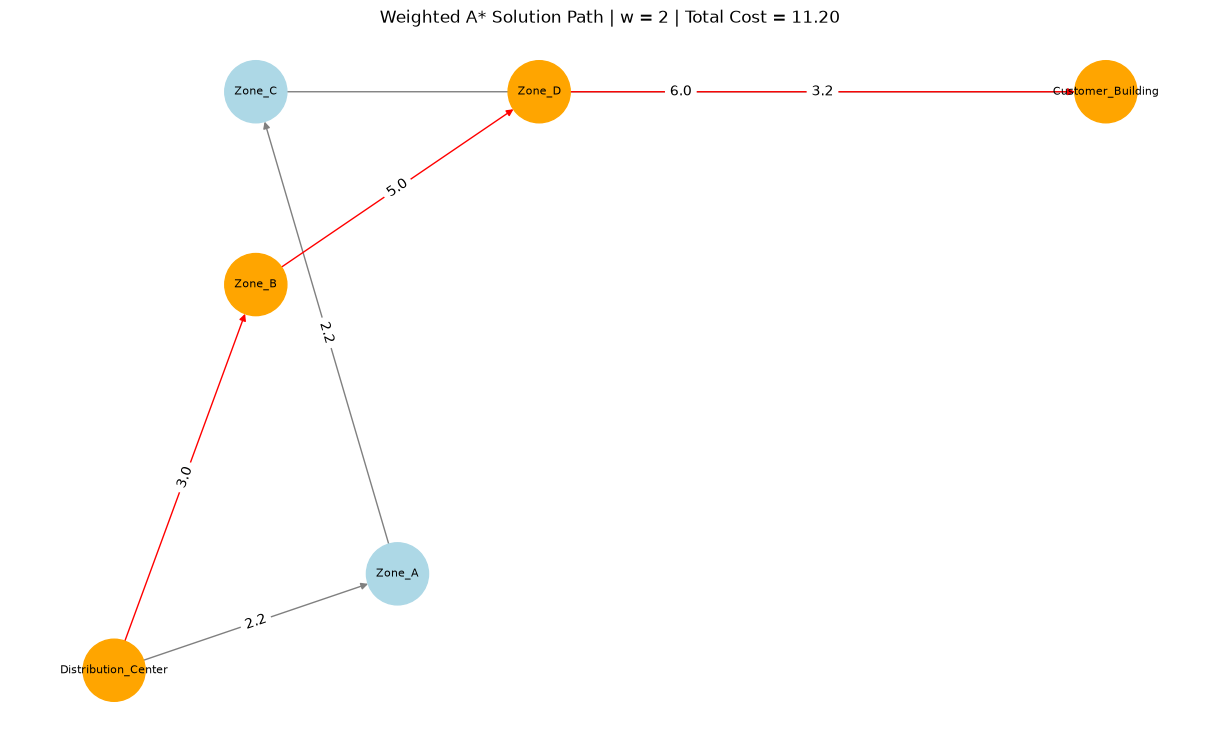

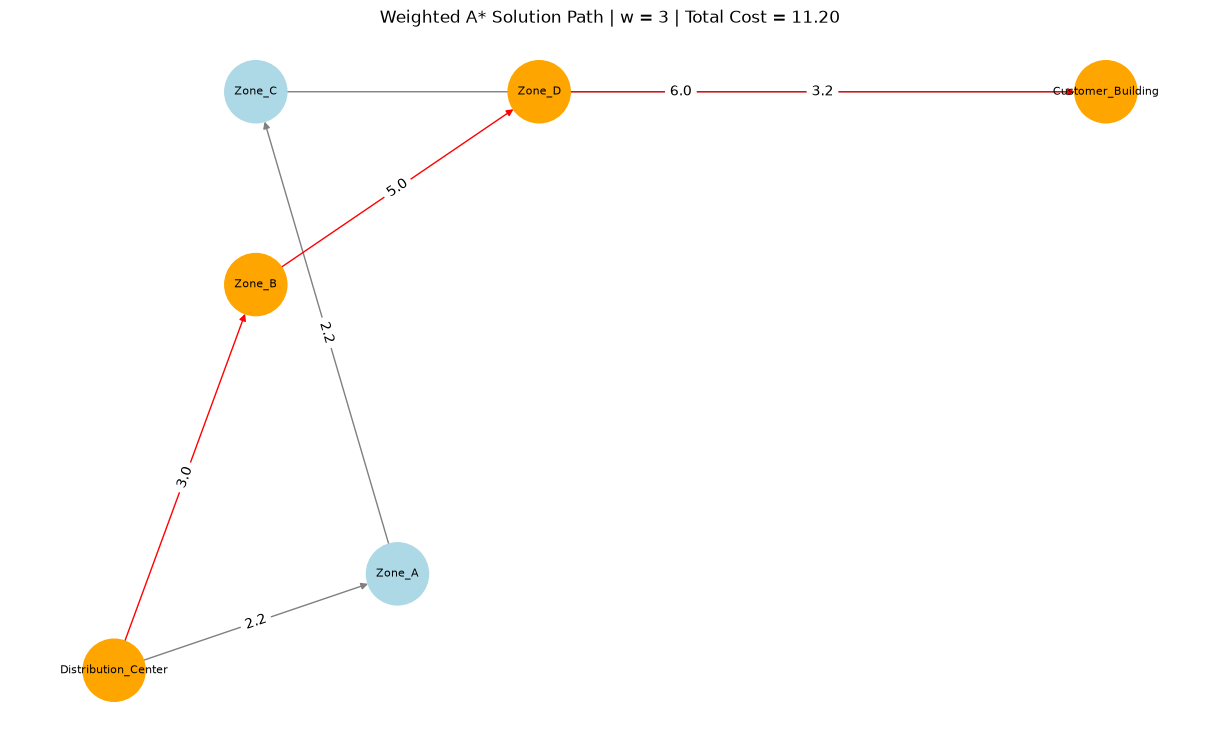

In [12]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for node, position in locations.items():
    G.add_node(node, pos=position)
for node, neighbors in graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

for w in weights:
    path, cost, _ = weighted_a_star(start, goal, graph, w)
    path_edges = list(zip(path, path[1:]))
    node_colors = ["orange" if n in path else "lightblue" for n in G.nodes()]
    edge_colors = ["red" if e in path_edges else "gray" for e in G.edges()]

    plt.figure(figsize=(12, 7))
    nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors,
            node_size=2000, font_size=8, arrows=True)
    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(G, pos, edge_labels)
    plt.title(f"Weighted A* Solution Path | w = {w} | Total Cost = {cost:.2f}")
    plt.axis("off")
    plt.show()

**Weighted A* comparison:** At weights 1 and 1.5, the drone takes `Distribution_Center → Zone_A → Zone_C → Customer_Building` for 10.40. At weights 2 and 3, it takes `Distribution_Center → Zone_B → Zone_D → Customer_Building` for 11.20. Larger weights emphasize `h(n)` over the travelled cost `g(n)` and expand fewer nodes here, but the route becomes more expensive. Weight 1 is normal A*; weights above 1 do not guarantee an optimal path.
